# Il ciclo completo, su un problema che si disegna

*Anatomia di un LLM* · capitolo 3, «I mattoni» · nel libro: §3.8 «Il ciclo, tutto intero» · script `01-06`, `scripts/01_06_training_loop.py`

**Dove siamo.** Qui i pezzi dei notebook precedenti si mettono insieme per la prima volta: un modello, una perdita, il gradiente, un passo. È lo stesso ciclo che nel capitolo 6 addestrerà il modello vero, su un problema abbastanza piccolo da vederlo tutto.

Quattro righe dentro un ciclo: guarda, sbaglia, chiedi in che direzione
muoverti, muoviti. E' lo stesso ciclo che nel capitolo 5 addestrera' il
modello vero, qui applicato a un problema abbastanza piccolo da vederlo tutto.

Si esegue con `python3 scripts/01_06_training_loop.py`
e dura circa 10 secondi.

> **Per riottenere i numeri del libro** esegui le celle in ordine, dalla prima. Il seme si fissa una volta sola, in `prepara()`: rieseguire una cella a metà cambia i numeri casuali di tutte quelle dopo.

[Apri in Colab](https://colab.research.google.com/github/fcollova/llm-anatomy/blob/main/notebooks/01_06_training_loop.ipynb) · la prima cella scarica il codice, se non lo trova accanto.

In [ ]:
# Porta il notebook nella cartella che contiene llm_anatomy/, da dovunque
# sia stato aperto: gli script si eseguono da li', e cosi' anche le celle.
import os
import subprocess
import sys
from pathlib import Path

radice = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "llm_anatomy").is_dir()), None)

if radice is None:
    # Il notebook e' stato aperto da solo, per esempio su Colab: il codice, il
    # testo e il modello addestrato si scaricano una volta, qui accanto.
    REPO, RAMO, CARTELLA = "fcollova/llm-anatomy", "main", ""
    copia = Path("anatomia-di-un-llm")
    if not copia.exists():
        esito = subprocess.run(
            ["git", "clone", "-q", "--depth", "1", "--branch", RAMO,
             f"https://github.com/{REPO}.git", str(copia)], capture_output=True)
        if esito.returncode != 0:
            raise SystemExit("Non riesco a scaricare il codice da github.com/"
                             + REPO + ": " + esito.stderr.decode()[-300:])
    radice = copia / CARTELLA

os.chdir(radice)
sys.path.insert(0, str(Path.cwd()))

In [ ]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from llm_anatomy.utils import (conta_parametri, figura, prepara, stile_figure,
                               titolo, verifica)

prepara()

N, PASSI = 1024, 2000

# Problema: due spirali intrecciate, separabili solo da un confine curvo.
def spirali(n: int):
    t = torch.linspace(0.4, 9.0, n // 2)     # una spirale e mezza per classe
    r = t / 3
    x0 = torch.stack([r * torch.cos(t), r * torch.sin(t)], dim=1)
    x1 = torch.stack([r * torch.cos(t + 3.14159), r * torch.sin(t + 3.14159)], dim=1)
    X = torch.cat([x0, x1]) + 0.04 * torch.randn(n, 2)
    y = torch.cat([torch.zeros(n // 2), torch.ones(n // 2)]).long()
    return X, y


X, y = spirali(N)
Xv, yv = spirali(256)
print(f"  dati: {tuple(X.shape)} esempi, due classi, confine non lineare")

[ambiente] torch 2.13.0+cpu  device=cpu  threads=8  seed=1337
  dati: (1024, 2) esempi, due classi, confine non lineare


### Il ciclo, in quattro righe

> **Nel libro, §3.8 «Il ciclo, tutto intero».** Che cosa succede, messi insieme i pezzi, quando una rete impara?

**Cosa guardare.** Non stampa niente: definisce il ciclo. Le quattro righe commentate sono previsione, errore, gradiente, passo.

In [ ]:
titolo("Il ciclo, in quattro righe")
def addestra(modello, nome: str) -> list[float]:
    ott = torch.optim.Adam(modello.parameters(), lr=0.02)
    perdita_fn = nn.CrossEntropyLoss()
    storia = []
    for passo in range(PASSI):
        logits = modello(X)                # 1. la previsione
        perdita = perdita_fn(logits, y)    # 2. quanto sbaglia
        ott.zero_grad(set_to_none=True)    #    via i gradienti vecchi
        perdita.backward()                 # 3. i gradienti nuovi
        ott.step()                         # 4. i pesi si spostano
        if (passo + 1) % 100 == 0:
            storia.append(perdita.item())
        if (passo + 1) % 500 == 0:
            with torch.no_grad():
                acc = (modello(Xv).argmax(1) == yv).float().mean().item()
            print(f"  {nome:<8} passo {passo + 1:5d}  "
                  f"perdita {perdita.item():.4f}  accuratezza val {acc:.3f}")
    return storia


Il ciclo, in quattro righe
--------------------------


### Un modello che non ce la fa

**Cosa guardare.** L'accuratezza ferma a 0,641 dal passo 500 in poi: una retta non separa due spirali.

In [ ]:
titolo("Un modello che non ce la fa")
lineare = nn.Linear(2, 2)
print(f"  parametri: {conta_parametri(lineare)}")
storia_lin = addestra(lineare, "lineare")


Un modello che non ce la fa
---------------------------
  parametri: 6


  lineare  passo   500  perdita 0.6568  accuratezza val 0.641
  lineare  passo  1000  perdita 0.6568  accuratezza val 0.641


  lineare  passo  1500  perdita 0.6568  accuratezza val 0.641
  lineare  passo  2000  perdita 0.6568  accuratezza val 0.641


### Lo stesso problema, con una piega

**Cosa guardare.** L'accuratezza a 1,000: con le pieghe in mezzo la rete segue le spirali.

**Prova a cambiare:** riduci gli strati nascosti da 32 a 3 numeri.

<details><summary>Che cosa succede</summary>

I parametri scendono da 1218 a 29 e l'accuratezza si ferma a 0,891: pieghe ce ne sono, ma troppo poche per seguire tutta la spirale.

</details>

In [ ]:
titolo("Lo stesso problema, con una piega")
rete = nn.Sequential(nn.Linear(2, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(),
                     nn.Linear(32, 2))
print(f"  parametri: {conta_parametri(rete)}")
storia_rete = addestra(rete, "rete")


Lo stesso problema, con una piega
---------------------------------
  parametri: 1218


  rete     passo   500  perdita 0.0003  accuratezza val 1.000


  rete     passo  1000  perdita 0.0001  accuratezza val 1.000


  rete     passo  1500  perdita 0.0000  accuratezza val 1.000


  rete     passo  2000  perdita 0.0000  accuratezza val 1.000


### Quanto è bravo, alla fine

*Questa parte non è stampata nel libro.*

**Cosa guardare.** Il confronto finale e la figura: la perdita lineare resta piatta, quella della rete scende a zero.


Quanto e' bravo, alla fine
--------------------------
  lineare: 0.641
  rete:    1.000
  [verifica superata] la rete non lineare supera nettamente il modello lineare


  [figura] outputs/figures/01-06_curva_perdita.pdf


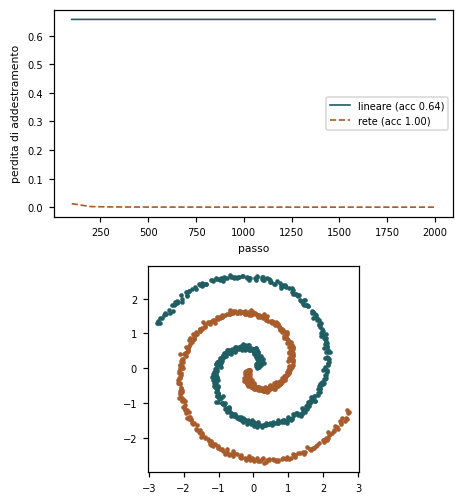

In [ ]:
titolo("Quanto e' bravo, alla fine")
with torch.no_grad():
    acc_lin = (lineare(Xv).argmax(1) == yv).float().mean().item()
    acc_rete = (rete(Xv).argmax(1) == yv).float().mean().item()
print(f"  lineare: {acc_lin:.3f}")
print(f"  rete:    {acc_rete:.3f}")
verifica(acc_rete > acc_lin + 0.2,
         "la rete non lineare supera nettamente il modello lineare")

fig, ax = plt.subplots(2, 1, figsize=(stile_figure(), 4.6))
passi = [100 * (i + 1) for i in range(len(storia_lin))]
ax[0].plot(passi, storia_lin, label=f"lineare (acc {acc_lin:.2f})")
ax[0].plot(passi, storia_rete, label=f"rete (acc {acc_rete:.2f})")
ax[0].set_xlabel("passo")
ax[0].set_ylabel("perdita di addestramento")
ax[0].legend()
ax[1].scatter(X[y == 0, 0], X[y == 0, 1], s=4)
ax[1].scatter(X[y == 1, 0], X[y == 1, 1], s=4)
ax[1].set_aspect("equal")
fig.tight_layout()
figura(fig, "01-06_curva_perdita")